# Diabetes Challenge

Your task today is to **analyze** the Kaggle "Pima Indians Diabetes Database" and to **predict** whether a patient has Diabetes or not.

## Task:
- Load the data from the database. The schema is called `diabetes`. To connect to the database you need to copy the `.env` file from the visualization or hands-on-ml repository into this repo. Explore the database, try to establish what the relationships between the tables are (1-1, 1-N, N-M). Explain to yourself and the group what data do you see and whether it makes sense. What JOINs are appropriate to use and why? 
- Use at least two different classification algorithms we have learned so far to predict Diabetes patients. 
- Discuss before you start with the modeling process which **evaluation metric** you choose and explain why.
- Implement a GridSearchCV or RandomizedSearchCV to tune the hyperparameters of your model.
- **Optional:** If you have time at the end, try to use sklearn's pipline module to encapsulate all the steps into a pipeline.

Don't forget to split your data in train and test set. And analyze your final model on the test data. It might also be necessary to scale your data in order to improve the performance of some of the models.


## Helpful links and advise:
- [sklearn documentation on hyperparameter tuning](https://scikit-learn.org/stable/modules/grid_search.html#grid-search)
- It might be helpful to check some sources on how to deal with imbalanced data. 
    * [8 Tactics to Combat Imbalanced Classes](https://machinelearningmastery.com/tactics-to-combat-imbalanced-classes-in-your-machine-learning-dataset/)
    * [Random-Oversampling/Undersampling](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/)


# Data Description

## Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

## Acknowledgements
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.

## About this dataset
The datasets consist of several medical predictor (independent) variables and one target (dependent) variable, Outcome. Independent variables include the number of pregnancies the patient has had, their BMI, insulin level, age, and so on. For the outcome class value 1 is interpreted as "tested positive for diabetes".

|Column Name| Description|
|:------------|:------------|
|Pregnancies|Number of times pregnant|
|Glucose|Plasma glucose concentration a 2 hours in an oral glucose tolerance test|
|BloodPressure|Diastolic blood pressure (mm Hg)|
|SkinThickness|Triceps skin fold thickness (mm)|
|Insulin|2-Hour serum insulin (mu U/ml)|
|BMI|Body mass index (weight in kg/(height in m)^2)|
|DiabetesPedigreeFunction| Diabetes pedigree function|
|Age| Age (years)|
|Outcome|Class variable (0 or 1) |

In [182]:
# Core libraries for data handling and numerical operations
import pandas as pd
import numpy as np


In [183]:
# Load the raw blood measurement data (one row per patient per measurement date)
df = pd.read_csv("data/blood_data.csv")

In [184]:
# Check the size of the raw dataset (rows, columns)
df.shape


(1771, 17)

In [185]:
# Keep only rows where the target (outcome) is known
real = df.dropna(subset=['outcome'])

# Compare the glucose-outcome correlation per measurement date
# to see which measurement round carries the most useful signal
for date, g in real.groupby('measurement_date'):
    print(date, round(g['glucose'].corr(g['outcome']), 3))

2022-12-01 -0.057
2022-12-13 0.467


In [186]:
# Size after removing rows without a target
real.shape

(1536, 17)

### we drop out the information of 2022-01

If we AVG the data the model would dilute.

In [187]:
# Keep only one measurement date (2022-12-13), so every patient appears once
# and we don't mix/average measurements from different points in time
real = real[real["measurement_date"] == "2022-12-13"]
print(real.columns)
print(real.shape)


Index(['insulin', 'glucose', 'bloodpressure', 'patientid', 'id',
       'measurement_date', 'id.1', 'Age', 'pregnancies', 'bmi',
       'skinthickness', 'patientid.1', 'id.2', 'diabetespedigreefunction',
       'outcome', 'patientid.2', 'id.3'],
      dtype='str')
(768, 17)


In [188]:
# Drop ID columns, duplicated join keys and the date - they carry no predictive information
real = real.drop(columns=["patientid", "id", "measurement_date", "id.1", "patientid.1", "id.2", "patientid.2", "id.3"])
print(real.columns)
print(real.shape)
real.head()


Index(['insulin', 'glucose', 'bloodpressure', 'Age', 'pregnancies', 'bmi',
       'skinthickness', 'diabetespedigreefunction', 'outcome'],
      dtype='str')
(768, 9)


,insulin,glucose,bloodpressure,Age,pregnancies,bmi,skinthickness,diabetespedigreefunction,outcome
1,0,148,72,50.0,6.0,33.6,35.0,0.627,1.0
3,0,85,66,31.0,1.0,26.6,29.0,0.351,0.0
5,0,183,64,32.0,8.0,23.3,0.0,0.672,1.0
7,94,89,66,21.0,1.0,28.1,23.0,0.167,0.0
9,168,137,40,33.0,0.0,43.1,35.0,2.288,1.0


## Before we build the model - we choose our expected goal

In [189]:
# Evaluation metrics: we focus on recall / F2, because missing a diabetes patient
# (false negative) is worse than a false alarm (false positive)
from sklearn.metrics import f1_score, fbeta_score, recall_score, precision_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt

In [190]:
# Separate features (X) from the target (y)
X = real.drop(columns="outcome")
y = real["outcome"]

In [191]:
# Split into train and test set (67/33).
# stratify=y keeps the same share of diabetes cases in both sets (imbalanced classes)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)
print(X_train.shape)
print(y_train.value_counts(normalize=True))  # class balance in the training set

# Drop insulin - too many missing / zero values to be reliable
X_train = X_train.drop(columns=['insulin'])
X_test = X_test.drop(columns=['insulin'])

(514, 8)
outcome
0.0    0.651751
1.0    0.348249
Name: proportion, dtype: float64


In [192]:
# Summary statistics of the training features (look for impossible zeros, outliers)
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
glucose,514.0,120.507782,31.511329,0.000,99.00000,116.00,140.0000,198.000
bloodpressure,514.0,69.346304,18.842135,0.000,62.00000,72.00,80.0000,122.000
Age,514.0,33.322957,11.575701,21.000,24.00000,29.50,41.0000,81.000
pregnancies,514.0,3.894942,3.367754,0.000,1.00000,3.00,6.0000,17.000
bmi,514.0,32.153502,7.892239,0.000,27.72500,32.40,36.4750,67.100
skinthickness,514.0,20.486381,15.589921,0.000,0.00000,23.00,32.0000,60.000
diabetespedigreefunction,514.0,0.478591,0.338724,0.084,0.24625,0.38,0.6305,2.329


In [193]:
# Share of missing values per column
X_train.isnull().mean().round(2)

# A value of 0 is physically impossible for these columns -> treat it as missing (train AND test)
cols = ["bmi", "bloodpressure", "glucose", "skinthickness"]
X_train[cols] = X_train[cols].replace(0, np.nan)
X_test[cols] = X_test[cols].replace(0, np.nan)

# Fill missing values with the median of the TRAINING data only (no leakage),
# and apply the same medians to the test set
train_medians = X_train[cols].median()
X_train[cols] = X_train[cols].fillna(train_medians)
X_test[cols] = X_test[cols].fillna(train_medians)


In [194]:
# Check the statistics again after cleaning the zeros
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
glucose,514.0,121.184825,30.128039,57.000,99.00000,116.00,140.0000,198.000
bloodpressure,514.0,72.287938,12.238802,24.000,64.00000,72.00,80.0000,122.000
Age,514.0,33.322957,11.575701,21.000,24.00000,29.50,41.0000,81.000
pregnancies,514.0,3.894942,3.367754,0.000,1.00000,3.00,6.0000,17.000
bmi,514.0,32.657782,6.775782,18.200,27.90000,32.40,36.4750,67.100
skinthickness,514.0,29.005837,8.253652,7.000,26.00000,29.00,32.0000,60.000
diabetespedigreefunction,514.0,0.478591,0.338724,0.084,0.24625,0.38,0.6305,2.329


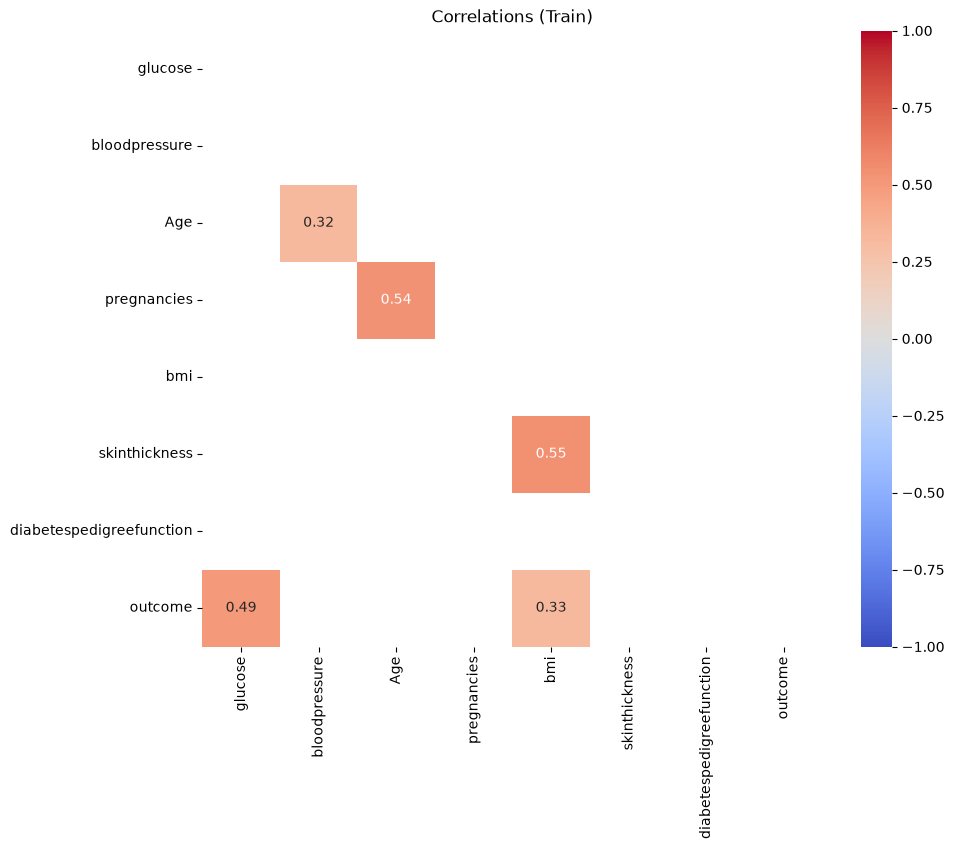

In [195]:
# Use only training data (no leakage) and add the outcome column
corr_df = X_train.copy()
corr_df['outcome'] = y_train
corr = corr_df.corr()

# Hide the upper triangle (it mirrors the lower one) and weak correlations (|r| < 0.3)
mask = np.triu(np.ones_like(corr, dtype=bool)) | (corr.abs() < 0.3)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations (Train)')
plt.show()

In [196]:
# Sanity checks: no missing values left, and train/test have identical columns
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print(X_train.columns.equals(X_test.columns))

0 0
True


## Making a Baseline model

In [197]:
# Simple rule-based baseline: predict diabetes if glucose is above a threshold.
# Every ML model should beat this to be worth using.
def baseline_model(X, threshold=130):
    return (X['glucose'] > threshold).astype(int)

y_pred_base = baseline_model(X_test)

# Evaluate the baseline on the test set
print("F2:       ", round(fbeta_score(y_test, y_pred_base, beta=2), 3))
print("Recall:   ", round(recall_score(y_test, y_pred_base), 3))
print("Precision:", round(precision_score(y_test, y_pred_base), 3))
print(confusion_matrix(y_test, y_pred_base))

F2:        0.586
Recall:    0.584
Precision: 0.591
[[129  36]
 [ 37  52]]


## prediction model - logistic regression / descision tree / knn

In [198]:
# Model selection / cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Classifiers we want to compare
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer

# imblearn's Pipeline is needed so that SMOTE is only applied during fit (training folds),
# never on the validation/test data
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [199]:
# Make sure the target is integer (0/1) for the classifiers and metrics
y_train = y_train.astype(int)
y_test = y_test.astype(int)

def make_pipe(model):
    return Pipeline([
        ("scaler", StandardScaler()),       # bring all features to the same scale
        ("smote", SMOTE(random_state=42)),  # oversample the minority class, training only
        ("model", model),
    ])

# F2 score weights recall twice as much as precision
f2 = make_scorer(fbeta_score, beta=2)
# 5-fold CV that keeps the class ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [200]:
# First comparison of the three models with default-ish settings.
# Comparing train vs. validation score shows over-/underfitting.
models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "Tree":   DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN":    KNeighborsClassifier(),
}
for name, m in models.items():
    s = cross_validate(make_pipe(m), X_train, y_train, scoring=f2, cv=cv, return_train_score=True)
    print(f"{name:7s} F2 val: {s['test_score'].mean():.3f}   train: {s['train_score'].mean():.3f}")

LogReg  F2 val: 0.695   train: 0.715
Tree    F2 val: 0.643   train: 0.835
KNN     F2 val: 0.703   train: 0.844


In [201]:
# Hyperparameter grids per model ("model__" prefix targets the pipeline step named "model")
grids = {
    "LogReg": (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),  # regularization strength
    "Tree":   (DecisionTreeClassifier(random_state=42), {"model__max_depth": [2, 3, 4, 5, 7, 10],
                                                          "model__min_samples_leaf": [1, 5, 10, 20]}),
    "KNN":    (KNeighborsClassifier(), {"model__n_neighbors": list(range(3, 40, 2)),  # odd k avoids ties
                                        "model__p": [1, 2]}),                         # 1 = Manhattan, 2 = Euclidean
}

# Tune each model with GridSearchCV on the training data, optimizing F2
best = {}
cv_scores = {}  # best CV F2 per model, used later to pick the final model
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipe(m), grid, scoring=f2, cv=cv, n_jobs=-1).fit(X_train, y_train)
    best[name] = gs.best_estimator_
    cv_scores[name] = gs.best_score_
    print(f"{name:7s} CV F2: {gs.best_score_:.3f}  {gs.best_params_}")

# Final evaluation of the tuned models on the untouched test set
for name, m in best.items():
    p = m.predict(X_test)
    print(f"{name:7s} TEST F2 {fbeta_score(y_test, p, beta=2):.3f}  "
          f"Recall {recall_score(y_test, p):.3f}  Precision {precision_score(y_test, p):.3f}")

LogReg  CV F2: 0.695  {'model__C': 1}
Tree    CV F2: 0.681  {'model__max_depth': 4, 'model__min_samples_leaf': 20}
KNN     CV F2: 0.770  {'model__n_neighbors': 23, 'model__p': 2}
LogReg  TEST F2 0.683  Recall 0.697  Precision 0.633
Tree    TEST F2 0.713  Recall 0.753  Precision 0.588
KNN     TEST F2 0.722  Recall 0.753  Precision 0.620


## Threshold tuning
By default `predict()` classifies a patient as diabetic if the predicted probability is >= 0.5.
Since missing a diabetes case is worse than a false alarm, a **lower threshold** can increase recall (and F2).
The threshold is chosen on the **training data** (out-of-fold predictions), so the test set stays untouched.

Final model: KNN
Best threshold: 0.31   CV F2: 0.791


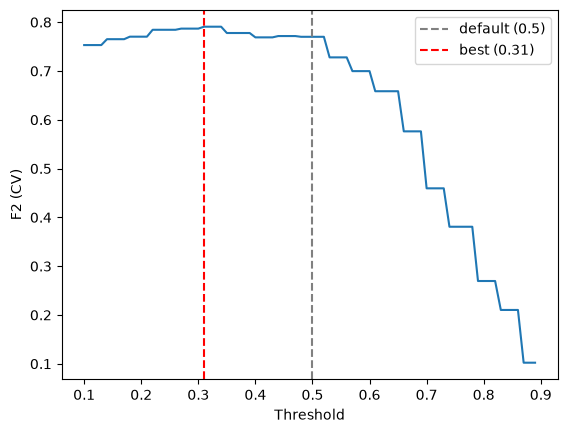

In [202]:
from sklearn.model_selection import cross_val_predict

# For every tuned model: out-of-fold probabilities on the training data
# (every training row is predicted by a model that did not see it)
thresholds = np.arange(0.10, 0.90, 0.01)
f2_curves = {}        # F2 for every threshold, per model
best_thresholds = {}  # threshold with the highest F2, per model
for name, model in best.items():
    proba_oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    f2_curves[name] = [fbeta_score(y_train, (proba_oof >= t).astype(int), beta=2) for t in thresholds]
    best_thresholds[name] = thresholds[np.argmax(f2_curves[name])]
    print(f"{name:7s} best threshold: {best_thresholds[name]:.2f}   CV F2: {max(f2_curves[name]):.3f}")

# Pick the final model by its tuned CV F2 (NOT by the test score)
best_name = max(f2_curves, key=lambda n: max(f2_curves[n]))
final_model = best[best_name]
best_threshold = best_thresholds[best_name]
print("\nFinal model:", best_name, f"(threshold {best_threshold:.2f})")

# Visualize how F2 changes with the threshold for each model
plt.figure(figsize=(9, 5))
for name, scores in f2_curves.items():
    line, = plt.plot(thresholds, scores, label=name)
    plt.scatter(best_thresholds[name], max(scores), color=line.get_color(), zorder=3)  # mark the best point
plt.axvline(0.5, color="grey", linestyle="--", label="default threshold (0.5)")
plt.xlabel("Threshold")
plt.ylabel("F2 (CV, train)")
plt.title("F2 vs. decision threshold per model")
plt.legend()
plt.show()

In [ ]:
# Final evaluation on the test set: default threshold vs. tuned threshold
proba = final_model.predict_proba(X_test)[:, 1]  # probability of class 1 (diabetes)

for label, t in [("default", 0.5), ("tuned", best_threshold)]:
    pred = (proba >= t).astype(int)
    print(f"{label:8s} t={t:.2f}  F2 {fbeta_score(y_test, pred, beta=2):.3f}  "
          f"Recall {recall_score(y_test, pred):.3f}  Precision {precision_score(y_test, pred):.3f}")
    print(confusion_matrix(y_test, pred), "\n")

## Model comparison: before vs. after tuning
All models are evaluated on the **same test set** at three stages:
1. **Default** - default hyperparameters, threshold 0.5
2. **GridSearch** - tuned hyperparameters, threshold 0.5
3. **GridSearch + threshold** - tuned hyperparameters, tuned threshold

The dashed line is the simple glucose baseline - a useful model should be clearly above it.

In [ ]:
# Collect the test F2 of every model at every stage
stages = ["Default", "GridSearch", "GridSearch + threshold"]
results = {}
for name in best:
    default_pipe = make_pipe(models[name]).fit(X_train, y_train)  # untuned model from the first comparison
    tuned_proba = best[name].predict_proba(X_test)[:, 1]
    results[name] = [
        fbeta_score(y_test, default_pipe.predict(X_test), beta=2),
        fbeta_score(y_test, best[name].predict(X_test), beta=2),
        fbeta_score(y_test, (tuned_proba >= best_thresholds[name]).astype(int), beta=2),
    ]
results_df = pd.DataFrame(results, index=stages).T  # rows = models, columns = stages
print(results_df.round(3))

# Grouped bar chart: one group per model, one bar per stage
baseline_f2 = fbeta_score(y_test, y_pred_base, beta=2)
ax = results_df.plot(kind="bar", figsize=(9, 5), rot=0)
ax.axhline(baseline_f2, color="black", linestyle="--", label=f"Baseline (glucose > 130): {baseline_f2:.2f}")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)  # show the value on top of each bar
ax.set_ylim(0, 1)
ax.set_ylabel("F2 (test)")
ax.set_title("Test F2 per model: before vs. after tuning")
ax.legend(loc="lower right")
plt.show()

In [175]:
# Logistic Regression without pipeline (no scaling, no SMOTE) - quick standalone check
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
# ypred = lr.predict(x_test)
# confusion_matrix(y_test, ypred)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [ ]:
# Code for cross validation